# Hierarchical and DBSCAN Clustering on the Wine Dataset

**Name:** Elkana Munganga  
**Course:** MSCS-634-M50 – Advanced Big Data and Data Mining  
**Assignment:** Hierarchical and DBSCAN Clustering Lab  
**Semester:** Fall 2026

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    homogeneity_score,
    completeness_score
)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

In [7]:
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Actual wine classes:", np.unique(y))

display(X.head())

Dataset shape: (178, 13)
Number of features: 13
Actual wine classes: [0 1 2]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [8]:
print("Dataset Information:")
X.info()

print("\nDescriptive Statistics:")
display(X.describe())

print("\nMissing Values:")
print(X.isnull().sum())

print("\nActual Class Distribution:")
print(pd.Series(y).value_counts().sort_index())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000



Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Actual Class Distribution:
0    59
1    71
2    48
Name: count, dtype: int64


In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("Standardized Dataset:")
display(X_scaled_df.head())

print("Mean of standardized features:")
print(X_scaled_df.mean().round(4))

print("\nStandard deviation:")
print(X_scaled_df.std(ddof=0).round(4))

Standardized Dataset:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


Mean of standardized features:
alcohol                        -0.0
malic_acid                     -0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                   0.0
flavanoids                     -0.0
nonflavanoid_phenols            0.0
proanthocyanins                -0.0
color_intensity                 0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0
dtype: float64

Standard deviation:
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines    1.0
proline                         1

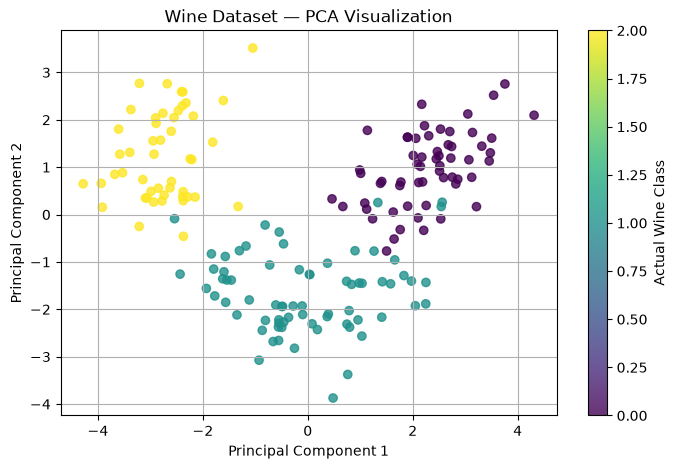

In [10]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.8
)

plt.title("Wine Dataset — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Actual Wine Class")
plt.grid(True)
plt.show()

## Step 1: Data Preparation and Exploration

I loaded the Wine dataset from scikit-learn, which contains 178 samples and 13 numerical features describing different chemical properties of wine. The dataset also includes three known wine classes that can be used to evaluate clustering performance.

I explored the dataset using pandas functions such as head(), info(), and describe(), and checked for missing values.

I standardized the features using StandardScaler because clustering algorithms rely on distances between data points. Without standardization, features with larger numerical ranges could have a greater influence on the clustering results.

Finally, I applied PCA to visualize the dataset in two dimensions while preserving the standardized 13-feature dataset for clustering.

In [11]:
hierarchical_results = []

for k in [2, 3, 4, 5, 6]:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    hierarchical_results.append({
        "Clusters": k,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Homogeneity Score": homogeneity_score(y, labels),
        "Completeness Score": completeness_score(y, labels)
    })

hierarchical_df = pd.DataFrame(hierarchical_results)

display(hierarchical_df.round(4))

,Clusters,Silhouette Score,Homogeneity Score,Completeness Score
0,2,0.2670,0.4441,0.7745
1,3,0.2774,0.7904,0.7825
2,4,0.2258,0.7904,0.6490
3,5,0.1867,0.8106,0.5762
4,6,0.1797,0.8348,0.5530


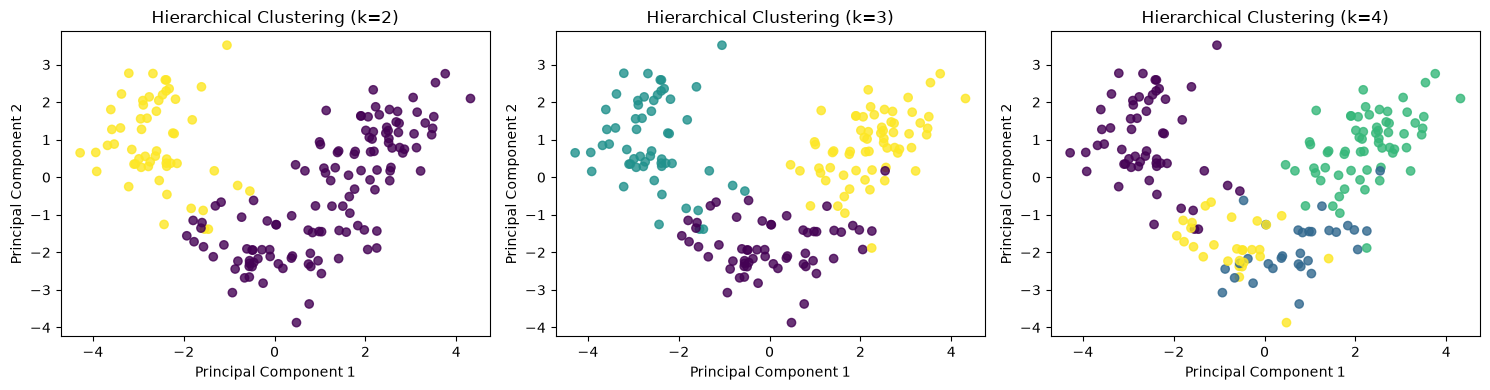

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, k in zip(axes, [2, 3, 4]):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        alpha=0.8
    )

    ax.set_title(f"Hierarchical Clustering (k={k})")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

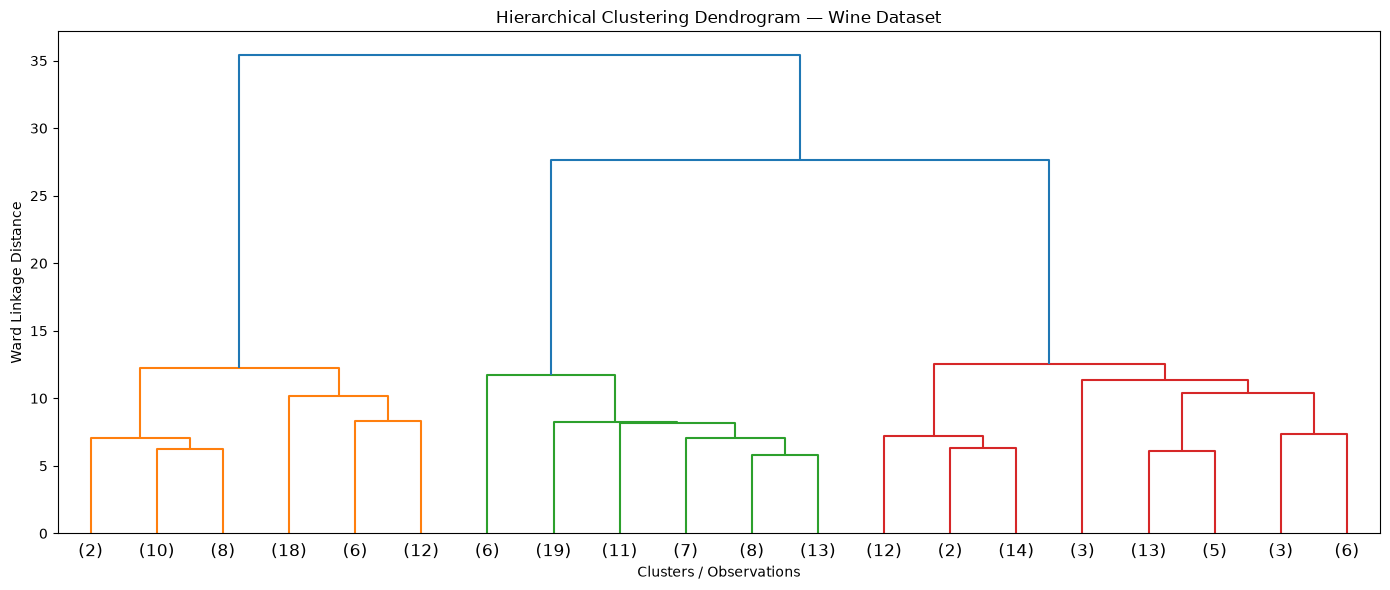

In [13]:
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram — Wine Dataset")
plt.xlabel("Clusters / Observations")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [14]:
best_hierarchical_row = hierarchical_df.loc[
    hierarchical_df["Silhouette Score"].idxmax()
]

best_k = int(best_hierarchical_row["Clusters"])

hierarchical_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

print("Best number of clusters:", best_k)
print("Silhouette Score:", round(best_hierarchical_row["Silhouette Score"], 4))
print("Homogeneity Score:", round(best_hierarchical_row["Homogeneity Score"], 4))
print("Completeness Score:", round(best_hierarchical_row["Completeness Score"], 4))

Best number of clusters: 3
Silhouette Score: 0.2774
Homogeneity Score: 0.7904
Completeness Score: 0.7825


## Step 2: Hierarchical Clustering

I applied Agglomerative Hierarchical Clustering using Ward linkage to the standardized Wine dataset. I tested different numbers of clusters, ranging from 2 to 6, and evaluated each configuration using the Silhouette, Homogeneity, and Completeness scores.

The scatter plots helped visualize how the observations were grouped under different cluster counts. I also generated a dendrogram to examine the hierarchical relationships between observations. The dendrogram shows how smaller groups are progressively merged into larger clusters.

I selected the cluster count with the highest Silhouette Score among the tested configurations. This provides a way to evaluate how well-separated and cohesive the resulting clusters are.

One advantage of hierarchical clustering is its ability to reveal relationships between groups through the dendrogram. However, it can become computationally expensive with larger datasets.

In [15]:
eps_values = [1.5, 2.0, 2.5, 3.0, 3.5]
min_samples_values = [3, 5, 10]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(labels == -1)

        # Calculate silhouette only when at least
        # two clusters exist among non-noise points.
        mask = labels != -1
        cluster_labels = labels[mask]

        if 2 <= len(set(cluster_labels)) < len(cluster_labels):
            silhouette = silhouette_score(
                X_scaled[mask],
                cluster_labels
            )
        else:
            silhouette = np.nan

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clusters": n_clusters,
            "Noise Points": n_noise,
            "Silhouette Score": silhouette,
            "Homogeneity Score": homogeneity_score(y, labels),
            "Completeness Score": completeness_score(y, labels)
        })

dbscan_df = pd.DataFrame(dbscan_results)

display(dbscan_df.round(4))

,eps,min_samples,Clusters,Noise Points,Silhouette Score,Homogeneity Score,Completeness Score
0,1.5,3,8,147,0.3311,0.1892,0.2510
1,1.5,5,0,178,NaN,0.0000,1.0000
2,1.5,10,0,178,NaN,0.0000,1.0000
3,2.0,3,5,64,0.2113,0.4423,0.3724
4,2.0,5,5,85,0.2405,0.3624,0.3247
5,2.0,10,1,139,NaN,0.2887,0.5963
6,2.5,3,1,23,NaN,0.0668,0.1885
7,2.5,5,1,24,NaN,0.0576,0.1581
8,2.5,10,2,32,0.3228,0.5045,0.5604
9,3.0,3,2,7,0.2392,0.0311,0.1347


In [16]:
eps_values = [1.5, 2.0, 2.5, 3.0, 3.5]
min_samples_values = [3, 5, 10]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(labels == -1)

        # Calculate silhouette only when at least
        # two clusters exist among non-noise points.
        mask = labels != -1
        cluster_labels = labels[mask]

        if 2 <= len(set(cluster_labels)) < len(cluster_labels):
            silhouette = silhouette_score(
                X_scaled[mask],
                cluster_labels
            )
        else:
            silhouette = np.nan

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clusters": n_clusters,
            "Noise Points": n_noise,
            "Silhouette Score": silhouette,
            "Homogeneity Score": homogeneity_score(y, labels),
            "Completeness Score": completeness_score(y, labels)
        })

dbscan_df = pd.DataFrame(dbscan_results)

display(dbscan_df.round(4))

,eps,min_samples,Clusters,Noise Points,Silhouette Score,Homogeneity Score,Completeness Score
0,1.5,3,8,147,0.3311,0.1892,0.2510
1,1.5,5,0,178,NaN,0.0000,1.0000
2,1.5,10,0,178,NaN,0.0000,1.0000
3,2.0,3,5,64,0.2113,0.4423,0.3724
4,2.0,5,5,85,0.2405,0.3624,0.3247
5,2.0,10,1,139,NaN,0.2887,0.5963
6,2.5,3,1,23,NaN,0.0668,0.1885
7,2.5,5,1,24,NaN,0.0576,0.1581
8,2.5,10,2,32,0.3228,0.5045,0.5604
9,3.0,3,2,7,0.2392,0.0311,0.1347


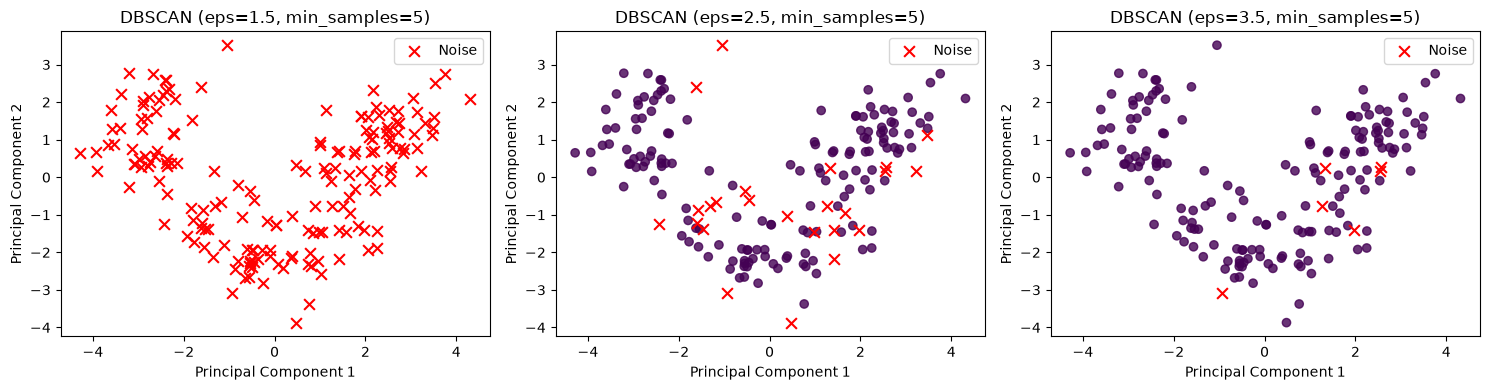

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, eps in zip(axes, [1.5, 2.5, 3.5]):

    model = DBSCAN(eps=eps, min_samples=5)
    labels = model.fit_predict(X_scaled)

    # Plot clusters
    mask = labels != -1

    ax.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        c=labels[mask],
        cmap="viridis",
        alpha=0.8
    )

    # Plot noise points in red
    ax.scatter(
        X_pca[~mask, 0],
        X_pca[~mask, 1],
        color="red",
        marker="x",
        s=60,
        label="Noise"
    )

    ax.set_title(f"DBSCAN (eps={eps}, min_samples=5)")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend()

plt.tight_layout()
plt.show()

In [18]:
valid_dbscan = dbscan_df.dropna(
    subset=["Silhouette Score"]
)

if not valid_dbscan.empty:

    best_dbscan_row = valid_dbscan.loc[
        valid_dbscan["Silhouette Score"].idxmax()
    ]

    best_eps = float(best_dbscan_row["eps"])
    best_min_samples = int(best_dbscan_row["min_samples"])

    dbscan_model = DBSCAN(
        eps=best_eps,
        min_samples=best_min_samples
    )

    dbscan_labels = dbscan_model.fit_predict(X_scaled)

    print("Best eps:", best_eps)
    print("Best min_samples:", best_min_samples)
    print("Clusters:", int(best_dbscan_row["Clusters"]))
    print("Noise Points:", int(best_dbscan_row["Noise Points"]))
    print("Silhouette Score:", round(best_dbscan_row["Silhouette Score"], 4))
    print("Homogeneity Score:", round(best_dbscan_row["Homogeneity Score"], 4))
    print("Completeness Score:", round(best_dbscan_row["Completeness Score"], 4))

else:
    best_dbscan_row = None
    dbscan_labels = None
    print("No configuration produced at least two non-noise clusters.")

Best eps: 1.5
Best min_samples: 3
Clusters: 8
Noise Points: 147
Silhouette Score: 0.3311
Homogeneity Score: 0.1892
Completeness Score: 0.251


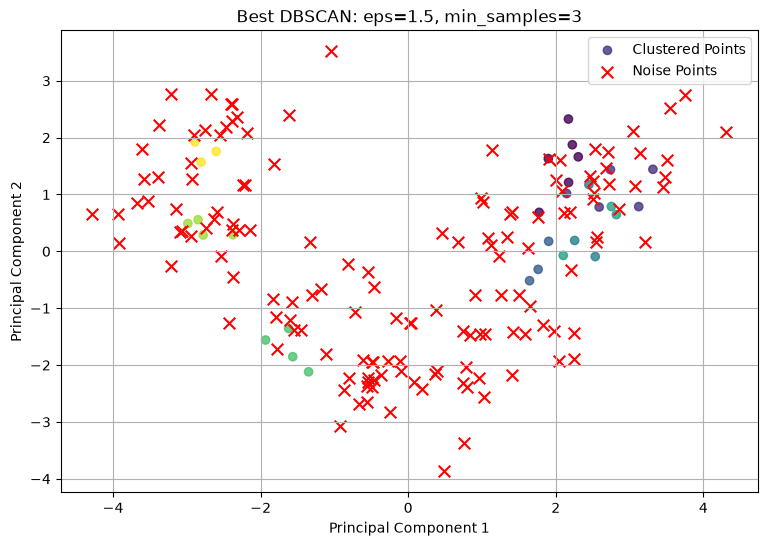

In [19]:
if dbscan_labels is not None:

    mask = dbscan_labels != -1

    plt.figure(figsize=(9, 6))

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        c=dbscan_labels[mask],
        cmap="viridis",
        alpha=0.8,
        label="Clustered Points"
    )

    plt.scatter(
        X_pca[~mask, 0],
        X_pca[~mask, 1],
        color="red",
        marker="x",
        s=70,
        label="Noise Points"
    )

    plt.title(
        f"Best DBSCAN: eps={best_eps}, "
        f"min_samples={best_min_samples}"
    )

    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("No valid DBSCAN model available to visualize.")

## Step 3: DBSCAN Clustering

I applied DBSCAN clustering to the standardized Wine dataset and tested different combinations of eps and min_samples.

The eps parameter controls the maximum neighborhood distance, while min_samples specifies the minimum number of observations required to form a dense region.

I observed how changing these parameters affected the number of clusters and noise points. Smaller eps values generally make it harder for observations to form clusters, while larger values can merge groups together.

I evaluated the results using the Silhouette Score, Homogeneity Score, and Completeness Score. The Silhouette Score measures cluster separation and cohesion, while Homogeneity and Completeness compare the clustering assignments with the known wine classes.

One advantage of DBSCAN is that it can identify noise points instead of forcing every observation into a cluster. However, selecting appropriate parameter values can be challenging, especially when the dataset contains groups with different densities.

In [20]:
comparison = [{
    "Algorithm": "Hierarchical",
    "Clusters": best_k,
    "Noise Points": 0,
    "Silhouette Score": best_hierarchical_row["Silhouette Score"],
    "Homogeneity Score": best_hierarchical_row["Homogeneity Score"],
    "Completeness Score": best_hierarchical_row["Completeness Score"]
}]

if best_dbscan_row is not None:
    comparison.append({
        "Algorithm": "DBSCAN",
        "Clusters": int(best_dbscan_row["Clusters"]),
        "Noise Points": int(best_dbscan_row["Noise Points"]),
        "Silhouette Score": best_dbscan_row["Silhouette Score"],
        "Homogeneity Score": best_dbscan_row["Homogeneity Score"],
        "Completeness Score": best_dbscan_row["Completeness Score"]
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Algorithm,Clusters,Noise Points,Silhouette Score,Homogeneity Score,Completeness Score
0,Hierarchical,3,0,0.2774,0.7904,0.7825
1,DBSCAN,8,147,0.3311,0.1892,0.2510


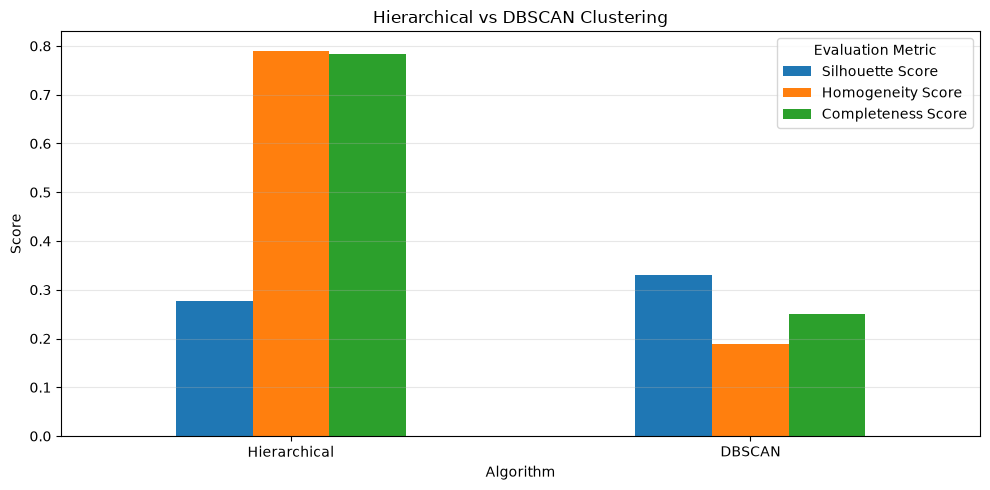

In [21]:
metrics = [
    "Silhouette Score",
    "Homogeneity Score",
    "Completeness Score"
]

comparison_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Hierarchical vs DBSCAN Clustering")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
print("Hierarchical Clustering — Different Cluster Counts")
display(hierarchical_df.round(4))

print("\nDBSCAN — Different Parameter Combinations")
display(dbscan_df.round(4))

print("\nBest Hierarchical Configuration:")
print("Number of clusters:", best_k)

if best_dbscan_row is not None:
    print("\nBest DBSCAN Configuration:")
    print("eps:", best_eps)
    print("min_samples:", best_min_samples)
    print("Number of clusters:", int(best_dbscan_row["Clusters"]))
    print("Noise points:", int(best_dbscan_row["Noise Points"]))

Hierarchical Clustering — Different Cluster Counts


,Clusters,Silhouette Score,Homogeneity Score,Completeness Score
0,2,0.2670,0.4441,0.7745
1,3,0.2774,0.7904,0.7825
2,4,0.2258,0.7904,0.6490
3,5,0.1867,0.8106,0.5762
4,6,0.1797,0.8348,0.5530



DBSCAN — Different Parameter Combinations


,eps,min_samples,Clusters,Noise Points,Silhouette Score,Homogeneity Score,Completeness Score
0,1.5,3,8,147,0.3311,0.1892,0.2510
1,1.5,5,0,178,NaN,0.0000,1.0000
2,1.5,10,0,178,NaN,0.0000,1.0000
3,2.0,3,5,64,0.2113,0.4423,0.3724
4,2.0,5,5,85,0.2405,0.3624,0.3247
5,2.0,10,1,139,NaN,0.2887,0.5963
6,2.5,3,1,23,NaN,0.0668,0.1885
7,2.5,5,1,24,NaN,0.0576,0.1581
8,2.5,10,2,32,0.3228,0.5045,0.5604
9,3.0,3,2,7,0.2392,0.0311,0.1347



Best Hierarchical Configuration:
Number of clusters: 3

Best DBSCAN Configuration:
eps: 1.5
min_samples: 3
Number of clusters: 8
Noise points: 147


## Step 4: Analysis and Insights

### Comparison of Hierarchical and DBSCAN Clustering

In this lab, I applied Agglomerative Hierarchical Clustering and DBSCAN to the Wine dataset from scikit-learn. The dataset contains 178 observations and 13 numerical features, which I standardized before applying both algorithms.

Hierarchical Clustering produced **3 clusters**, with a Silhouette Score of **0.2774**, a Homogeneity Score of **0.7904**, and a Completeness Score of **0.7825**. These results suggest that the algorithm was reasonably successful at grouping wines according to their underlying classes.

DBSCAN produced **8 clusters and 147 noise points**, with a Silhouette Score of **0.3311**, a Homogeneity Score of **0.1892**, and a Completeness Score of **0.2510**. Although DBSCAN achieved a higher Silhouette Score, it classified approximately 82.6% of the observations as noise. Its Silhouette Score was calculated using only non-noise observations, making a direct comparison with Hierarchical Clustering less meaningful.

### Influence of Parameters

For Hierarchical Clustering, I experimented with different numbers of clusters ranging from 2 to 6. Changing the cluster count affected how the observations were grouped and how well the clusters matched the actual wine classes.

For DBSCAN, I tested different values of `eps` and `min_samples`. Smaller neighborhood distances generally resulted in more noise points, while larger distances allowed more observations to form clusters. The results demonstrated how sensitive DBSCAN can be to parameter selection, especially when working with standardized data containing multiple features.

### Strengths and Weaknesses

Hierarchical Clustering performed better overall in this experiment. It identified three clusters, which matched the number of known wine classes, and achieved substantially higher Homogeneity and Completeness scores. The dendrogram also provided a useful visualization of how observations were grouped.

DBSCAN's main advantage was its ability to identify noise and unusual observations without requiring a predefined number of clusters. However, the large number of noise points limited its effectiveness for this dataset. Its low Homogeneity and Completeness scores indicated that the resulting groups did not closely match the known wine classes.

### Conclusion

Based on my results, **Hierarchical Clustering was the more effective algorithm for the Wine dataset**. It grouped all observations into three clusters and demonstrated stronger agreement with the actual wine classes.

DBSCAN showed the importance of parameter tuning, but its selected configuration excluded too many observations to provide a useful overall segmentation.

This experiment helped me understand that a higher Silhouette Score does not automatically mean a clustering algorithm is better. It is important to consider multiple evaluation metrics, the number of clusters, and how many observations are included in the final clustering results.